# Perform linear regression to identify metabolites with differing abundances in those using antibiotics
These regressions will have all covariates selected in `get_abx_use_covariates` notebook. In addition, we will be able to look at those who use antibiotics in the last three versus the last twelve months. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import arivale_data_interface as adi
adi.apply_isb_config()

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
# Now you can import your file
from regression_functions import *

# Import and process data

In [2]:
# Read and sort abx use data
abx_covar = pd.read_csv("data/abx_recency_covariates_all.csv")
abx_covar = abx_covar.sort_values(by="days_in_program")

# Read and sort metab information
metabolites = adi.get_snapshot("metabolomics_corrected").sort_values(by="days_in_program")

misanns_ids = {'100020423':'100022485',
               '100020419':'100022482',
               '100020425':'100022480',
               '100020427':'100022479'}
metabolites = metabolites.rename(misanns_ids, axis='columns')

metabolite_features = metabolites.columns[8:]
metabolites.days_in_program = metabolites.days_in_program.astype("float64")

In [3]:
abx_covar

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,age,BMI_CALC,hx_t2dm,hx_gestational,gluc_dysreg,eGFR,centered_eGFR,centered_BMI,abx_recency_three,abx_recency_twelve
0,01071494,-0.216793,-0.110133,-0.088564,0.055447,0.006009,-40.0,No,No,none,...,49.0,30.598898,No,No,0,86.366123,-10.582038,2.736353,0,0
1,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,46.0,35.662071,No,No,0,115.435836,18.487675,7.799525,0,1
2,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,54.0,19.483497,No,No,0,103.067192,6.119031,-8.379048,0,0
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,45.0,26.120098,No,No,0,88.199673,-8.748488,-1.742448,0,0
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,32.0,22.668163,No,No,0,96.720816,-0.227344,-5.194382,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2661,01181682,0.058783,-0.010586,-0.012099,-0.051793,0.031362,629.0,No,Yes,twelve,...,49.0,24.676735,No,No,0,70.589153,-26.359008,-3.185811,0,1
2662,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,...,42.0,32.413454,No,No,0,98.708674,1.760513,4.550909,1,0
2663,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,...,47.0,23.957596,No,No,0,100.360100,3.411939,-3.904949,1,0
2664,01382823,0.065718,-0.021335,-0.035135,0.089997,0.031969,752.0,No,No,three,...,47.0,30.724246,No,No,0,107.280676,10.332515,2.861700,1,0


In [4]:
covar_columns = abx_covar.columns.tolist()

In [5]:
anns_snapshot = pd.read_csv("data/metabolites_snapshot_updated.csv")

In [6]:
# # Run this cell for generating a table of id and days for Noa for metBMI
# mets_ids_days = metabolites.copy()
# mets_ids_days.rename(columns={'days_in_program':'days_in_program_mets'}, inplace=True)

# mets = pd.merge_asof(
#     abx_covar, mets_ids_days, 
#     by="public_client_id", 
#     left_on="days_in_program",
#     right_on="days_in_program_mets",
#     direction="nearest", 
#     tolerance=30.0).dropna(subset=metabolite_features, how="all")

# mets_ids_days_df = mets[['public_client_id','days_in_program_mets']].copy()
# mets_ids_days_df.to_csv('data/ids_days_for_metBMI.csv', index=False)

In [7]:
# anns_snapshot[anns_snapshot.CHEMICAL_NAME == 'alpha-hydroxyisocaproate']

In [8]:
metabolites_merged = pd.merge_asof(
    abx_covar, metabolites, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset=metabolite_features, how="all")
metabolite_features = metabolites.columns[metabolites.columns.isin(metabolite_features)]
metabolites_merged.head()

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,999953114,999953157,999953172,999953266,999953267,999954831,999954832,999954834,999954839,999954840
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,0.736626,1.928746,NaN,1.151177,0.899924,0.982119,0.992174,1.020387,0.369896,1.418072
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,0.452953,NaN,NaN,1.864759,1.299824,1.037411,1.049852,1.109848,NaN,0.789232
5,01324699,0.059337,-0.024547,-0.040044,0.094414,0.034026,-2.0,No,No,three,...,0.714330,0.749277,0.910968,2.190841,1.156268,0.941816,0.736709,0.773792,1.650485,1.782973
6,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,0.649365,0.882981,NaN,NaN,1.404256,0.987746,1.037036,0.877633,NaN,0.826977
7,01994483,0.054177,0.014071,0.020539,-0.093049,-0.005232,0.0,No,No,none,...,1.092669,0.894790,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.782441


In [9]:
# Getting rid of the most sparse columns
bad = metabolites_merged[metabolite_features].isnull().sum() / metabolites_merged.shape[0] > 0.3
metabolite_features = bad[~bad].index
metabolites_merged = metabolites_merged.drop(columns=bad[bad].index)
metabolites_merged.shape

(1599, 996)

In [10]:
# Standardizing data
metabolites_merged[metabolite_features] = np.log(metabolites_merged[metabolite_features])
metabolites_merged[metabolite_features] = metabolites_merged[metabolite_features].apply(lambda x: (x - x.mean()) / x.std())
metabolites_merged.rename(columns=dict(zip(metabolite_features, "metabolite_" + metabolite_features)), inplace=True)
metabolite_features = "metabolite_" + metabolite_features
metabolites_all = metabolite_features

In [11]:
assert (metabolites_merged[metabolite_features].mean().abs() < 1e-6).all()

In [12]:
metabolites_merged['abx_recency'].value_counts() #.tolist()

abx_recency
none      1031
twelve     352
three      216
Name: count, dtype: int64

In [13]:
len(metabolites_all)

969

# Run Regressions

In [14]:
metabolites_merged.to_csv("data/metabolites_merged_used_for_regressions.csv", index=False)

In [15]:
# For all regressions in this notebook we will use the same features and df
args = metabolite_features
df = metabolites_merged.set_index(['public_client_id','days_in_program'])

In [16]:
len(metabolite_features)

969

array([[<Axes: title={'center': '0'}>]], dtype=object)

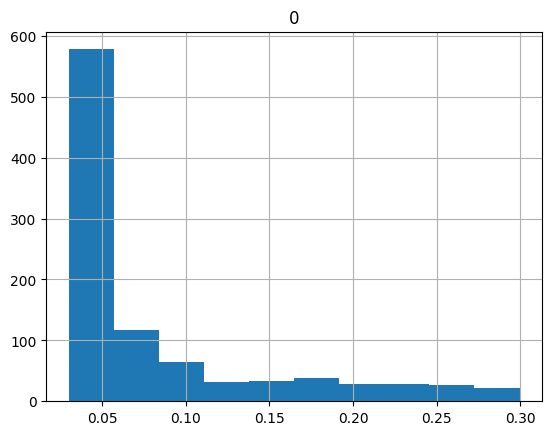

In [17]:
pd.DataFrame(metabolites_merged[metabolite_features].isna().sum() / metabolites_merged[metabolite_features].shape[0]).hist()

In [18]:
# Define formula for results and look at the difference between including GFR vs not 
formula_mets = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
               "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) +"
               "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")
formula_mets_dysreg = ("{feature} ~ C(sex) + age + BMI_CALC + C(abx_recency_three) + " 
               "C(abx_recency_twelve) + C(meds_cholesterol) + C(meds_blood_sugar) + C(hx_t2dm) + C(hx_gestational) +"
               "PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")
abx_term_three = "C(abx_recency_three)[T.1]"
abx_term_twelve = "C(abx_recency_twelve)[T.1]"
chol_term = "C(meds_cholesterol)[T.Yes]"
sugar_term = "C(meds_blood_sugar)[T.Yes]"

## Three month regression

In [19]:
tests_threemo = run_tests(args, df, formula_mets, abx_term_three)
tests_threemo_dysreg = run_tests(args, df, formula_mets_dysreg, abx_term_three)

Output()

Output()

In [20]:
sig_three = tests_threemo[tests_threemo["q"]<0.1].sort_values(by='q')

In [21]:
# len(tests_three_anns_sig)

In [22]:
# Merge onto annotations
tests_three_anns = pd.merge(tests_threemo, anns_snapshot, on="feature")
tests_three_anns_sig = (tests_three_anns[tests_three_anns["q"]<0.1]
                        [['beta', 'se', 'n', 'q','CHEMICAL_NAME', 'SUB_PATHWAY']])

tests_three_anns_dys = pd.merge(tests_threemo_dysreg, anns_snapshot, on="feature")
tests_three_anns_sig_dys = (tests_three_anns_dys[tests_three_anns_dys["q"]<0.1]
                        [['beta', 'se', 'n', 'q','CHEMICAL_NAME', 'SUB_PATHWAY']])

In [23]:
larger_cohort_sig = set(tests_three_anns_sig['CHEMICAL_NAME'])
add_dys_sig = set(tests_three_anns_sig_dys['CHEMICAL_NAME'])

In [24]:
larger_cohort_sig.intersection(add_dys_sig)

{'2-hydroxy-3-methylvalerate',
 '2-hydroxybutyrate/2-hydroxyisobutyrate',
 '2-piperidinone',
 '3-(3-hydroxyphenyl)propionate',
 '3-(4-hydroxyphenyl)lactate',
 '3-hydroxy-2-ethylpropionate',
 '3-hydroxydecanoate',
 '3-hydroxylaurate',
 '3-hydroxymyristate',
 '3-hydroxyoctanoate',
 '3-phenylpropionate (hydrocinnamate)',
 '4-hydroxyhippurate',
 '4-methyl-2-oxopentanoate',
 '5-hydroxyhexanoate',
 '5alpha-androstan-3beta,17alpha-diol disulfate',
 'X - 12216',
 'X - 12544',
 'X - 15728',
 'X - 17335',
 'X - 21353',
 'acetylcarnitine (C2)',
 'alpha-hydroxyisocaproate',
 'alpha-hydroxyisovalerate',
 'alpha-ketobutyrate',
 'cinnamoylglycine',
 'dodecadienoate (12:2)*',
 'glutarate (C5-DC)',
 'hippurate',
 'hydantoin-5-propionate',
 'indolepropionate',
 'isoursodeoxycholate',
 'phenyllactate (PLA)'}

In [25]:
add_dys_sig - larger_cohort_sig

{'3-hydroxyhexanoate', 'citrate'}

In [26]:
larger_cohort_sig - add_dys_sig

set()

In [27]:
# tests_three_anns_sig_dys.sort_values(by=['beta','q'])

In [28]:
# # Checks which bile acids were tested
# tests_three_anns.dropna()[tests_three_anns['SUB_PATHWAY'].dropna().str.contains("Bile")]['CHEMICAL_NAME'].tolist()
# tests_three_anns.dropna()[tests_three_anns['SUB_PATHWAY'].dropna().str.contains("Bile")]

## Regressions to extract betas from 3-12 months

In [29]:
# Now find the betas for 12 months
tests_twelvemo = run_tests(args, df, formula_mets, abx_term_twelve)

Output()

In [30]:
tests_twelve_anns = pd.merge(tests_twelvemo, anns_snapshot, on="feature")
tests_twelve_anns_sig = (tests_twelve_anns[tests_twelve_anns["q"]<0.1]
                         [['beta','se','n', 'q', 'CHEMICAL_NAME', 'SUB_PATHWAY']])

In [31]:
sig_hists_twelve_list = tests_twelve_anns[tests_twelve_anns["q"]<0.1]['feature'].tolist()

### Save lists of significant hits

In [32]:
# Includes metabolite_ prefix
sig_hists_twelve_list = tests_twelve_anns[tests_twelve_anns["q"]<0.1]['feature'].tolist()
sig_hists_three_list = tests_three_anns[tests_three_anns["q"]<0.1]['feature'].tolist()
sig_hits_metab_number = list(set(sig_hists_three_list + sig_hists_twelve_list))

# Just metabolon id
sig_metabolon_ids = [s.split("_", 1)[1] for s in sig_hits_metab_number]

# By chemical name
all_sig_metabs_names = list(set(list(tests_twelve_anns_sig.CHEMICAL_NAME) +
                                list(tests_three_anns_sig.CHEMICAL_NAME)))

In [33]:
# all_sig_metabs_names
len(sig_hits_metab_number)

34

In [34]:
sig_hits_metab_number

['metabolite_240',
 'metabolite_100000551',
 'metabolite_100000882',
 'metabolite_100001541',
 'metabolite_100000774',
 'metabolite_100001083',
 'metabolite_100002021',
 'metabolite_100002488',
 'metabolite_100008928',
 'metabolite_999946398',
 'metabolite_999946510',
 'metabolite_999946666',
 'metabolite_100020478',
 'metabolite_339',
 'metabolite_100001112',
 'metabolite_999947708',
 'metabolite_100001148',
 'metabolite_100002253',
 'metabolite_100002514',
 'metabolite_796',
 'metabolite_100004295',
 'metabolite_100000014',
 'metabolite_100001300',
 'metabolite_100000997',
 'metabolite_100001423',
 'metabolite_999946613',
 'metabolite_100000010',
 'metabolite_100000802',
 'metabolite_999947820',
 'metabolite_100000773',
 'metabolite_100001170',
 'metabolite_100001624',
 'metabolite_100000706',
 'metabolite_999948001']

## Extract beta coefficients associated with cholesterol and blood sugar lowering medication use

In [35]:
tests_chol = run_tests(args, df, formula_mets, chol_term)
tests_chol_anns = pd.merge(tests_chol, anns_snapshot, on="feature")
tests_chol_anns_subset = tests_chol_anns[tests_chol_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]

Output()

In [36]:
tests_sugar = run_tests(args, df, formula_mets, sugar_term)
tests_sugar_anns = pd.merge(tests_sugar, anns_snapshot, on="feature")
tests_sugar_anns_subset = tests_sugar_anns[tests_sugar_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]

Output()

## Get beta and q-value dataframes for plotting in R

In [37]:
metabs_betas = (tests_three_anns[tests_three_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]
                [['CHEMICAL_NAME','beta']].rename(columns={'beta':'abx_three'}))

# Add twelve month betas
metabs_betas = metabs_betas.merge(tests_twelve_anns[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'abx_twelve'})

metabs_betas = metabs_betas.merge(tests_chol_anns_subset[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'chol_meds'})

metabs_betas = metabs_betas.merge(tests_sugar_anns_subset[['CHEMICAL_NAME','beta']].copy(),
                                  how='left', on='CHEMICAL_NAME').rename(
    columns={'beta':'blood_sugar_meds'})

metabs_betas

,CHEMICAL_NAME,abx_three,abx_twelve,chol_meds,blood_sugar_meds
0,3-(4-hydroxyphenyl)lactate,-0.213787,-0.117430,-0.070555,0.093941
1,glutarate (C5-DC),0.302153,0.081044,-0.005269,0.246936
2,alpha-ketobutyrate,-0.235046,-0.018865,0.068983,0.489881
3,3-phenylpropionate (hydrocinnamate),-0.343529,-0.179521,-0.082576,-0.061306
4,hippurate,-0.262174,-0.196912,-0.173505,-0.159983
5,4-methyl-2-oxopentanoate,-0.208599,-0.106307,0.074137,0.544634
6,alpha-hydroxyisocaproate,-0.213506,-0.101245,-0.022021,0.218990
7,3-hydroxyoctanoate,-0.228937,-0.147866,0.070133,0.887619
8,phenyllactate (PLA),-0.240545,-0.134656,-0.039017,0.094937
9,acetylcarnitine (C2),-0.273789,-0.061022,-0.013758,0.058746


In [38]:
metabs_q_values = (tests_three_anns[tests_three_anns.CHEMICAL_NAME.isin(all_sig_metabs_names)]
                   [['CHEMICAL_NAME','q']].rename(columns={'q':'abx_three'}))

# Add twelve month betas
metabs_q_values = metabs_q_values.merge(tests_twelve_anns[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'abx_twelve'})

metabs_q_values = metabs_q_values.merge(tests_chol_anns_subset[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'chol_meds'})

metabs_q_values = metabs_q_values.merge(tests_sugar_anns_subset[['CHEMICAL_NAME','q']].copy(),
                                        how='left', on='CHEMICAL_NAME').rename(
    columns={'q':'blood_sugar_meds'})

metabs_q_values

,CHEMICAL_NAME,abx_three,abx_twelve,chol_meds,blood_sugar_meds
0,3-(4-hydroxyphenyl)lactate,0.052096,0.648441,0.541636,6.171590e-01
1,glutarate (C5-DC),0.014049,0.734646,0.978931,1.660810e-01
2,alpha-ketobutyrate,0.062482,0.936265,0.616763,1.483222e-03
3,3-phenylpropionate (hydrocinnamate),0.004280,0.409025,0.549273,8.390610e-01
4,hippurate,0.027316,0.170090,0.108268,4.224044e-01
5,4-methyl-2-oxopentanoate,0.072594,0.717502,0.541636,6.522537e-05
6,alpha-hydroxyisocaproate,0.052096,0.717502,0.870477,1.568660e-01
7,3-hydroxyoctanoate,0.068131,0.609503,0.600788,4.592670e-10
8,phenyllactate (PLA),0.022733,0.609503,0.763476,6.206182e-01
9,acetylcarnitine (C2),0.026822,0.811200,0.945589,8.252185e-01


In [39]:
metabs_betas.to_csv("data/rh_metabs_betas.csv", index=False)
metabs_q_values.to_csv("data/rh_metabs_qs.csv", index=False)

## Perform unbiased lab ~ metabolite*abx regression

In [40]:
labs_clean = pd.read_csv("data/clincal_chems_abx_users_clean.csv")

In [41]:
## Identify which clinical chemistry tests were offered by each vendor
quest = labs_clean[labs_clean['vendor'] == 'Quest']
labcorp = labs_clean[labs_clean['vendor'] == 'LCA']

In [42]:
lab_features = labs_clean.columns[30:].tolist()
cols = lab_features + ['vendor']

In [43]:
# cols

In [44]:
labs_clean.set_index('public_client_id', inplace=True)
labs_for_merge = labs_clean[cols].reset_index()

In [60]:
metabolite_features = metabolites_merged.columns[27:]

In [45]:
labs_mets = metabolites_merged.merge(labs_for_merge, on='public_client_id', how='left')

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,UREANITROGEN,URICACID,VITAMIND_25_OHTOT,VITAMIND3_25_OH,WHITECELLCOUNT,ZINC,ZINC_RBC,QUICKI,EPA_AA,vendor
0,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,18.0,6.8,31.4,NaN,6.5,1203.0,NaN,0.335478,0.083333,LCA
1,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,15.0,5.5,37.0,NaN,4.1,1107.0,NaN,0.378068,0.076923,LCA
2,01324699,0.059337,-0.024547,-0.040044,0.094414,0.034026,-2.0,No,No,three,...,14.0,4.9,23.0,23.0,4.6,1070.0,10.7,0.357227,NaN,Quest
3,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,21.0,4.3,28.2,NaN,4.4,1291.0,NaN,0.380269,0.128713,LCA
4,01994483,0.054177,0.014071,0.020539,-0.093049,-0.005232,0.0,No,No,none,...,20.0,6.9,31.0,NaN,3.4,1537.0,NaN,0.401477,0.183673,LCA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,01065944,-0.506563,-0.215852,-0.163353,-0.039495,0.074177,134.0,No,No,twelve,...,14.0,4.2,19.9,NaN,4.8,1357.0,NaN,0.359467,0.109091,LCA
1595,01129614,-0.259367,0.903496,-0.166992,0.082477,0.124521,141.0,No,No,three,...,8.0,4.8,16.2,NaN,7.5,NaN,NaN,0.263039,0.031746,LCA
1596,01282093,0.055284,-0.017160,-0.032840,0.049724,0.022521,179.0,No,No,none,...,12.0,3.6,11.4,NaN,4.9,NaN,NaN,0.343106,0.038835,LCA
1597,01448060,0.064413,-0.019391,-0.042273,0.056574,0.038743,373.0,No,No,three,...,11.0,5.0,84.8,NaN,3.3,NaN,NaN,0.380049,0.052632,LCA


In [53]:
labs_mets['abx_year'] = labs_mets['abx_recency'].apply(lambda x: "none" if x == "none" else "past_year")

In [46]:
not_offered_quest = quest[lab_features].isna().all().index[quest[lab_features].isna().all()].tolist()

In [48]:
# not_offered_labcorp

In [49]:
not_offered_labcorp = labcorp[lab_features].isna().all().index[labcorp[lab_features].isna().all()].tolist()

In [50]:
individual_vendors = not_offered_labcorp + not_offered_quest
shared_labs = list(set(lab_features) - set(individual_vendors))

In [51]:
not_offered_quest_tests = []
not_offered_labcorp_tests = []
shared_tests = []

In [61]:
# # Labcorp only 
# for chemistry in not_offered_quest:
#     temp = run_year_interaction_regressions(
#         args,                                # Metabolite abundances
#         labs_mets,                           # df
#         chemistry,                           # clinical chemistry
#         categorical_pred = False
#     )
#     temp['chemistry'] = chemistry
#     not_offered_quest_tests.append(temp)

In [62]:
# not_offered_quest_tests

In [ ]:
# Quest only 
for chemistry in not_offered_labcorp:
    temp = run_year_interaction_regressions(
        args,                                # Metabolite abundances
        labs_mets,                           # df
        chemistry,                           # clinical chemistry
        categorical_pred = False
    )
    temp['chemistry'] = chemistry
    not_offered_labcorp_tests.append(temp)

In [ ]:
# Shared only 
for chemistry in shared_labs:
    temp = run_year_interaction_regressions(
        args,                                # Metabolite abundances
        labs_mets,                           # df
        chemistry,                           # clinical chemistry
        categorical_pred = False
    )
    temp['chemistry'] = chemistry
    shared_tests.append(temp)

In [ ]:
shared_tests